In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
from gliders.utils import sigma_clipping, grow_mask, get_profile_from_border, normalize_data
from gliders.artifacts import detect_artifacts, get_artifact_flag, clean_artifacts, detect_and_clean_artifacts
from gliders.background_suppressor import suppress_background, show_all_methods
from scipy.stats import norm
from scipy.signal import convolve2d
from astropy.convolution import Gaussian2DKernel

def extract_band_data(hdu_list, verbose=True, bands_to_analyze = ['r']):
    all_bands = {}
    all_img_diffs = {}
    all_img_areas = {}
    all_weights = {}
    all_wgh_diffs = {}
    all_wgh_areas = {}
    ref_hdu = None
    for hdu in hdu_list:
        try:
            header = hdu._header
            if verbose:
                print(header)
            band = header.get("BAND")
            if band not in bands_to_analyze: continue
            image_type = header.get("IMAGETYP")
            imagew = header.get("IMAGEW")
            imageh = header.get("IMAGEH")

            if band is None or image_type is None or imagew is None or imageh is None:
                continue  # Skip if essential header info is missing

            img_dim_diff = abs(imagew - imageh)
            img_area = imagew * imageh

            if image_type == "image":
                if band not in all_bands or img_area > all_img_areas[band] or (img_area == all_img_areas[band] and img_dim_diff < all_img_diffs[band]):
                    all_bands[band] = hdu.copy().data
                    all_img_areas[band] = img_area
                    all_img_diffs[band] = img_dim_diff
                    ref_hdu = hdu.header

            elif image_type == "invvar":
                w_map = hdu.copy().data
                w_map[w_map == 0] += 1  # Avoid division by zero
                weight = 1 / np.sqrt(w_map)
                if band not in all_weights or img_area > all_wgh_areas[band] or (img_area == all_wgh_areas[band] and img_dim_diff < all_wgh_diffs[band]):
                    all_weights[band] = weight
                    all_wgh_areas[band] = img_area
                    all_wgh_diffs[band] = img_dim_diff

        except Exception as e:
            print(f"Skipped HDU due to error: {e}")

    return all_bands, all_weights, ref_hdu

file_dir = "C:/Astrostuff/PhD/Data/DESI FITS/"
artif_file = "C:/Astrostuff/PhD/Data/My_data/DESI_New_mergers.csv"
artif_catalog = Table.read(artif_file, format = "csv", converters = {"object_id":str})
print(len(artif_catalog))
print(artif_catalog)

3692
    object_id         ra      dec       z    ...    I    merger_predicted  ES
----------------- --------- -------- ------- ... ------- ---------------- ---
39627902957912363 211.09828  4.71795 0.02977 ... 0.41312                1   1
39632991730798910 253.11914 35.41754 0.05766 ...  0.2024                1   1
39627829528234714 150.37899  1.68886 0.09869 ... 0.01352                1   1
39627830664894213  218.2308  1.86938 0.02998 ... 0.58443                1   1
39633427988745611 271.28566 63.42304  0.0915 ...  0.2459                1   1
39627758090851335  212.4838 -1.23884  0.0248 ... 0.47045                1   1
39633104083616306 152.75604 41.58966 0.05861 ... 0.60419                1   1
39627877821449269 150.00236  3.67734 0.07391 ... 0.03693                1   1
39627773882401920   73.5449 -0.39993 0.05467 ... 0.15411                1   1
39633321931571417 185.66454 55.08292 0.03664 ... 0.28208                1   1
              ...       ...      ...     ... ...     ...   

39627848754926153
No config provided. Using default config.


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_8996\4276820289.py:44: UserWarning: No configuration object was provided. Will use default configuration.
  deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, wcs=wcs, use_photo_type = False, show_plots=True, verbose=True)


Looking for nearby sources with available redshift
Deblending by source photometric type is not activated.
ONE: []


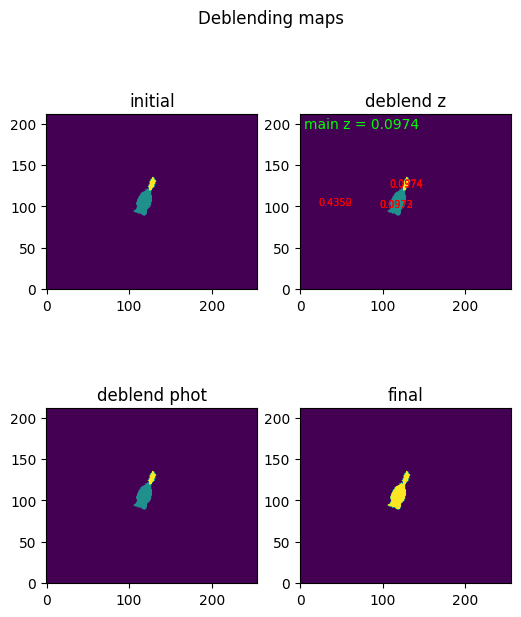

Detected 1 sources after de-blending.
39633465871697509
No config provided. Using default config.


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_8996\4276820289.py:44: UserWarning: No configuration object was provided. Will use default configuration.
  deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, wcs=wcs, use_photo_type = False, show_plots=True, verbose=True)


Looking for nearby sources with available redshift
Deblending by source photometric type is not activated.
ONE: [np.int32(10)]


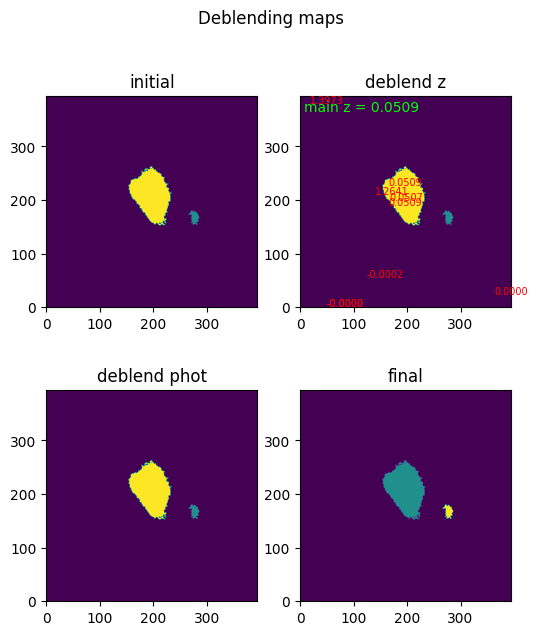

Detected 2 sources after de-blending.
39627805939466963
No config provided. Using default config.


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_8996\4276820289.py:44: UserWarning: No configuration object was provided. Will use default configuration.
  deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, wcs=wcs, use_photo_type = False, show_plots=True, verbose=True)


Looking for nearby sources with available redshift
Deblending by source photometric type is not activated.
ONE: [np.int32(5), np.int32(7)]


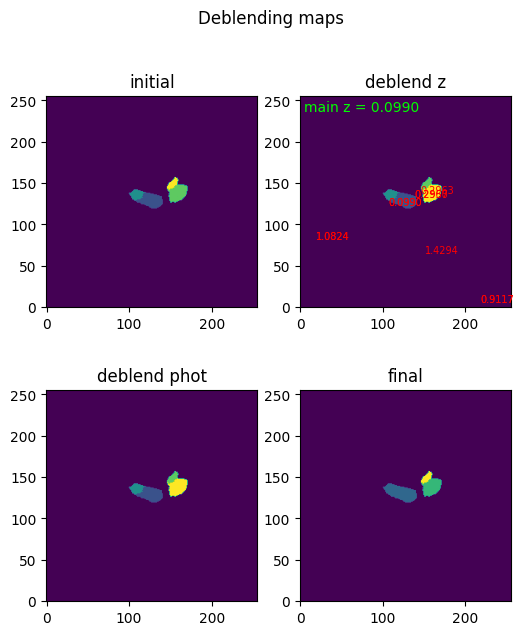

Detected 3 sources after de-blending.
39633470514790576
39632986764742121
No config provided. Using default config.


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_8996\4276820289.py:44: UserWarning: No configuration object was provided. Will use default configuration.
  deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, wcs=wcs, use_photo_type = False, show_plots=True, verbose=True)


Looking for nearby sources with available redshift
Deblending by source photometric type is not activated.
ONE: []


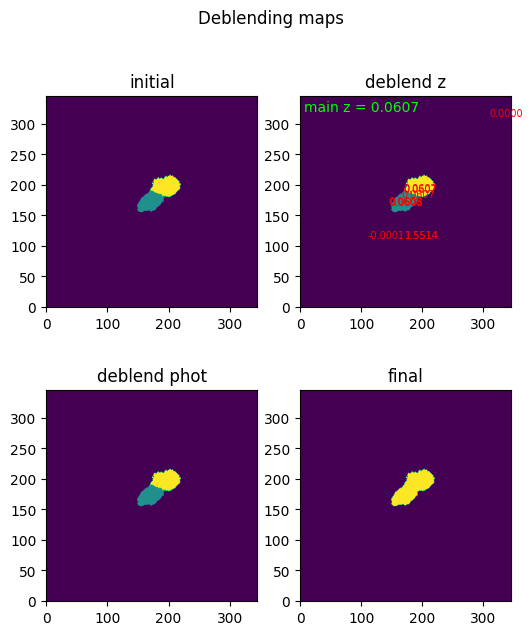

Detected 1 sources after de-blending.
39633136505585922
No config provided. Using default config.


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_8996\4276820289.py:44: UserWarning: No configuration object was provided. Will use default configuration.
  deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, wcs=wcs, use_photo_type = False, show_plots=True, verbose=True)


Looking for nearby sources with available redshift
Deblending by source photometric type is not activated.
ONE: []


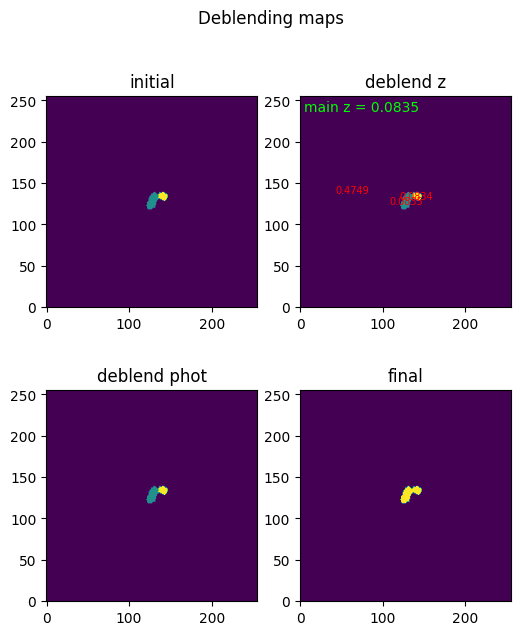

Detected 1 sources after de-blending.
39627817436057197
No config provided. Using default config.


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_8996\4276820289.py:44: UserWarning: No configuration object was provided. Will use default configuration.
  deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, wcs=wcs, use_photo_type = False, show_plots=True, verbose=True)


Looking for nearby sources with available redshift
Deblending by source photometric type is not activated.
ONE: []


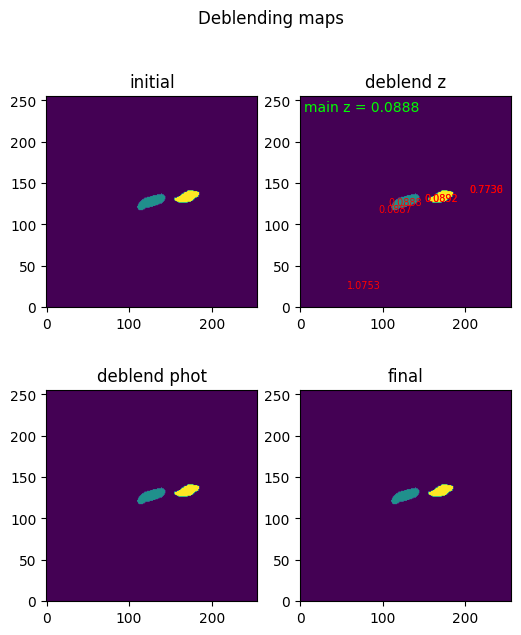

Detected 2 sources after de-blending.
39633293271894039
No config provided. Using default config.


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_8996\4276820289.py:44: UserWarning: No configuration object was provided. Will use default configuration.
  deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, wcs=wcs, use_photo_type = False, show_plots=True, verbose=True)


Looking for nearby sources with available redshift
Deblending by source photometric type is not activated.
ONE: [np.int32(7)]


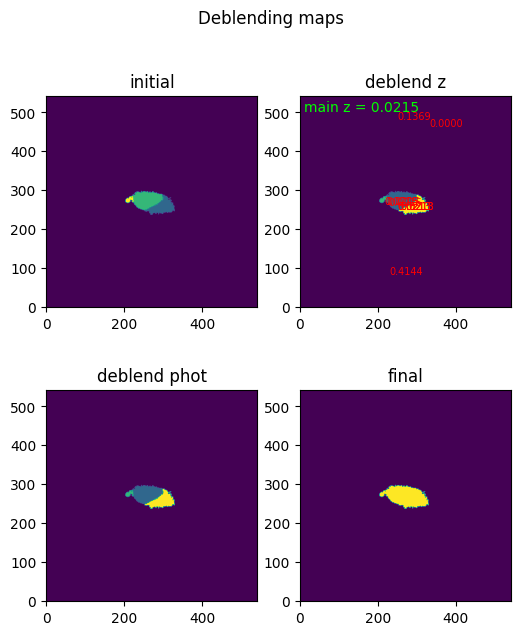

Detected 1 sources after de-blending.
39627770304661746
No config provided. Using default config.


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_8996\4276820289.py:44: UserWarning: No configuration object was provided. Will use default configuration.
  deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, wcs=wcs, use_photo_type = False, show_plots=True, verbose=True)


Looking for nearby sources with available redshift
Deblending by source photometric type is not activated.
ONE: [np.int32(4)]


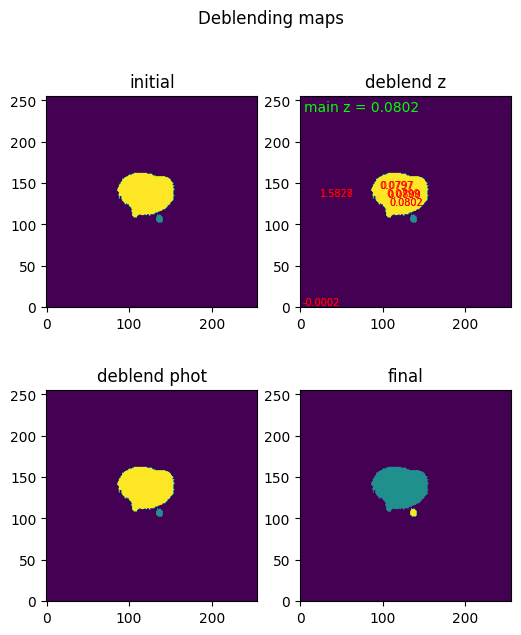

Detected 2 sources after de-blending.


In [3]:
for ii, object_info in enumerate(artif_catalog[140:]):
    object_id = object_info[0]
    print(object_id)
    obj_coords = (object_info[1],object_info[2])
    redshift = object_info[3]
    bands = ['r'] #,'g']
    file_name = f"{object_id}_{"".join(bands)}.fits"
    sources_name = f"{object_id}_sources.fits"

    file_path = os.path.join(file_dir, file_name)
    sources_path = os.path.join(file_dir, sources_name)
    try:
        with fits.open(file_path) as hdu_list:
            # hdu_list.info()
            all_bands, all_weights, ref_header = extract_band_data(hdu_list, verbose=False, bands_to_analyze=bands)
    except:
        continue

    with fits.open(sources_path) as hdul:
        data = hdul[1].data
        as_table = Table(data)
    wcs = WCS(ref_header)
    tractor_x_pix, tractor_y_pix = wcs.all_world2pix(as_table['ra'], as_table['dec'], 0)  # origin=0 for Python indexing
    source_x_pix, source_y_pix = wcs.all_world2pix(obj_coords[0], obj_coords[1], 0)  # origin=0 for Python indexing
    source_pos = (np.round(source_x_pix), np.round(source_y_pix))
    as_table['xcentroid'] = tractor_x_pix
    as_table['ycentroid'] = tractor_y_pix
    phot_sources = as_table['type','xcentroid','ycentroid']
    image = all_bands['r']


    if obj_coords[1] > 32.375:
        pix_scale = 1.72
    else:
        pix_scale = 1

    # if ii < 2:
    #     continue

    from gliders.deblending import deblend_and_mask_sources
    from gliders.pipeline import update_detections
    image_convolved, seg_map, main_source_segment = update_detections(image, source_min_pix = 100)
    wcs = WCS(ref_header)
    deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, wcs=wcs, use_photo_type = False, show_plots=True, verbose=True)
    # plt.imshow(image - image.min(), norm = "log")
    # plt.show()

    # fig, ax = plt.subplots(2, 2, figsize=(6, 6))
    # ax[0,0].imshow(clean_image_denorm_ref, norm = "log", cmap = "inferno") #, bins = 30)
    # ax[0,1].imshow(pushed_denorm_ref_a, norm = "log", cmap = "inferno") #, bins = 30)
    # ax[1,0].imshow(pushed_denorm_ref_b, norm = "log", cmap = "inferno") #, bins = 30)
    # ax[1,1].imshow(pushed_denorm_ref_c, norm = "log", cmap = "inferno") #, bins = 30)
    # # ax[0,0].hist(clean_image_flat, bins = 60)
    # # ax[0,1].hist(pushed_image_a_flat, bins = 60)
    # # ax[1,0].hist(pushed_image_b_flat, bins = 60)
    # # ax[1,1].hist(pushed_image_c_flat, bins = 60)
    # plt.show()
    if ii >= 8:
        break
